# Расчёт проточной части газовой турбины — по порядку книги
**Михальцев В.Е., Моляков В.Д. «Теория и проектирование газовой турбины», ч. 1** (МГТУ им. Баумана, 2006),
порядок расчёта п. 1–153 (стр. 84–93), профилирование — гл. 7, решётки — гл. 8.

**Как пользоваться**
1. Исходные данные цикла (T\*г, p\*г, расход, p_т …) берутся из `Turbinis-Cycle` автоматически (раздел 1). Меняются там.
2. Все **выбираемые** величины книги собраны в разделе 2 — **меняйте только эту ячейку**. Рядом с каждой — номер пункта и рекомендация книги.
   Величины, задаваемые по ступеням, — списки `[ст. 1, ст. 2, …, ст. z]`, длина списка = `z`.
3. *Kernel → Restart & Run All*. Разделы 3–9 идут в порядке книги; в конце — контроль и сводка.

**Чем расчёт отличается от «ручного» по книге** (это видно в разделе 6):
* степень реактивности каждой ступени подбирается так, чтобы выход был осевой, α₂ = 90° (п. 99: «при отклонении α₂ … параметры пересчитываются»);
* частота вращения n уточняется итерацией: площадь A_т за последней ступенью (п. 9) после расчёта ступеней получается другой → пересчёт n (п. 11);
* расход воздуха подбирается так, чтобы мощность на валу была равна заданной в цикле (у ступеней книги КПД иной, чем принят в цикле).

Вариант по умолчанию: π\*к = 11, **z = 4**, сопловая лопатка 1-й ступени **l_c1 > 20 мм** при полном подводе (лёгкая 1-я ступень на малом диаметре).
Исходный блокнот `Main_Turbinis_Calc.ipynb` не изменён.

In [1]:
%matplotlib inline
import math
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

for _p in (Path.cwd(), Path.cwd() / "Turbinis-Calc"):
    if (_p / "cycle_link.py").exists():
        sys.path.insert(0, str(_p))
from cycle_link import load_cycle

Ц = load_cycle()  # выполняет блокнот Turbinis-Cycle и возвращает его переменные

## 1. Исходные данные из цикла
Задаются в `Turbinis-Cycle` (здесь не меняются). Вариант книги «задано статическое давление за турбиной p_т».

In [2]:
R = Ц["R"]  # газовая постоянная, Дж/(кг·К)
calc_cp = Ц["calc_cp_kerosene"]  # средняя c_p продуктов сгорания керосина (методичка цикла)
р = Ц["р"]  # результаты цикла в выбранной точке

π_к = float(Ц["π_к_выб"])  # степень повышения давления компрессора
α_г = float(р["α"])  # коэффициент избытка воздуха
T_г_полн = float(Ц["T_г_полн"])  # T*г - температура газа перед турбиной, К
p_г_полн = Ц["σ_г"] * Ц["σ_вх"] * Ц["p_а_полн"] * π_к  # p*г = σ_г σ_вх p*в π*к, Па
p_т = Ц["π_с"] * Ц["p_а"]  # p_т - статическое давление за турбиной, Па
G_в = float(Ц["G_в_выб"])  # расход воздуха (первое приближение), кг/с
g_т = float(р["g_т"])  # G_т/G_в = (1 + g_m)(1 - g_ут - g_охл)
g_охл = float(Ц["g_охл"])  # отбор на охлаждение дисков и корпуса
g_воз = float(Ц["g_воз"])  # часть охлаждающего воздуха, возвращаемая в проточную часть за 1-й ступенью
G_c1 = G_в * g_т  # расход через СА 1-й ступени, кг/с
G_л_ост = G_в * (g_т + g_воз)  # расход через ступени 2...z, кг/с
η_м = float(Ц["η_м_тур"])  # механический КПД (п. 152)
η_р = float(Ц["η_р"])  # КПД редуктора
L_к = float(р["L_к"])  # работа компрессора, Дж/кг
N_зад = float(Ц["N_зад"])  # мощность на валу, Вт
η_т_полн_цикл = float(р["η_т"])  # η*т, принятый в цикле
N_т_цикл = G_в * р["L_т"] * (g_т + g_воз) * η_м  # мощность турбины в цикле, Вт

pd.Series(
    {
        "π*к": π_к,
        "T*г, К": T_г_полн,
        "p*г, кПа": p_г_полн / 1e3,
        "p_т (за турбиной), кПа": p_т / 1e3,
        "G_в (цикл), кг/с": G_в,
        "G_c1 (через СА 1-й ступени), кг/с": G_c1,
        "g_охл (диски, корпус), %": g_охл * 100,
        "g_воз (возврат за 1-й ступенью), %": g_воз * 100,
        "α (избыток воздуха)": α_г,
        "η_м": η_м,
        "N на валу, кВт": N_зад / 1e3,
        "η*т цикла": η_т_полн_цикл,
    }
).to_frame("значение")

,значение
π*к,11.000000
"T*г, К",1250.000000
"p*г, кПа",1059.170007
"p_т (за турбиной), кПа",105.352000
"G_в (цикл), кг/с",0.523700
"G_c1 (через СА 1-й ступени), кг/с",0.520816
"g_охл (диски, корпус), %",1.500000
"g_воз (возврат за 1-й ступенью), %",0.900000
α (избыток воздуха),3.937576
η_м,0.992500


## 2. Выбираемые параметры — **меняйте только эту ячейку**
Номер пункта — по порядку расчёта книги (стр. 84–93). Списки — по ступеням `[ст. 1, …, ст. z]`.

In [3]:
# ======================= Частота вращения (п. 1-12) =======================
η_л_ожид = 0.90  # п. 5   лопаточный КПД турбины для оценки T_т (задаётся)
c_та = float(Ц["c_т"])  # п. 8   осевая скорость за турбиной, м/с - первое приближение (из цикла), дальше уточняется
σ_л = float(Ц["σ_л_62"])  # п. 10  напряжение растяжения в РЛ, МПа. Из цикла (п. 6.2: u_т = 350 м/с -> ~239 МПа); можно числом, напр. 160
k_n = float(Ц["K_n"])  # п. 11  коэффициент формы лопатки, ~6,8e-6 (стр. 56)

# ============ Основные размеры многоступенчатой турбины (п. 45-69) ============
l_т_D_т = float(Ц["l_т_to_D_т"])  # п. 45  l_т/D_т последней ступени (книга: <= 1/3,5...1/3)
z = 4  # п. 54  принятое число ступеней (формула п. 54 - только для сравнения)
D_ст = [0.65, 1.0, 1.0, 1.0]  # п. 48  средний диаметр ступени D/D_т (последняя = 1). Меньше D -> длиннее лопатка, но меньше u
y0 = 0.54  # п. 51  оптимальное u/c0 (для оценки z по п. 54)
μ = 0.9  # п. 53, 131  коэффициент использования скорости c2 следующей ступенью
π_веса = [0.25, 1.0, 1.0, 1.0]  # п. 55  распределение теплоперепада: ln(p*0/p2) ступени ~ вес (последняя - по p_т)
α1_ст = [11.0, 12.0, 12.0, 18.0]  # п. 58  угол выхода из СА, град (обычно > 16...17°; малые турбины 11...14°, стр. 34-35)
lb_c, lb_л = 2.25, 2.75  # п. 65-66  удлинение l/b_a СА и РК (одноступенчатые: 2...2,5 и 2,5...3, стр. 61)
δа_к_ba = 0.22  # п. 67-68  осевой зазор δ_a/b_a = 0,20...0,25 (стр. 62)

# ====================== Ступень (п. 70-129) ======================
φ = 0.97  # п. 37, 73  коэффициент скорости СА: 0,95...0,97 (стр. 34)
ψ = 0.96  # п. 89  коэффициент скорости РК: книга чисел не даёт (стр. 37: зависит от формы канала, угла поворота, ρ); типично 0,92...0,96
α2_цель = 90.0  # п. 99  угол выхода из ступени: осевой выход у всех ступеней
κ_ст = [0.85, 0.85, 0.85, 1.2]  # п. 96  c2a = κ·c1a. У последней ступени κ > 1: выше c_т -> меньше A_т -> больше n
δ_отн = 0.005  # п. 113  радиальный зазор δ_л/l (книга: 0,007...0,01, стр. 63; с сотовыми вставками меньше)
δ_мин = 0.2e-3  # п. 113  наименьший радиальный зазор, м (сотовые вставки <= 0,2 мм, стр. 12)
ε_парц = 1.0  # п. 119  степень парциальности (полный подвод)

# ============ Профилирование по радиусу (гл. 7) ============
закон_ст = ["α1", "Γ", "Γ", "Γ"]  # "Γ" - постоянная циркуляция, "α1" - постоянный угол α1 (разд. 7.3)
ρ_таблица = ([1 / 9, 1 / 6, 1 / 4, 1 / 3], [0.2, 0.3, 0.4, 0.5])  # п. 56  ρ_ср = f(l/D) (стр. 58) - начальное приближение
ρ_макс = 0.6  # наибольшая степень реактивности при подборе
ρ_корня_мин = 0.05  # у корня ρ >= 0,05...0,1 (стр. 58)
α1_мин_корня = 11.0  # град: α1 у корня >= 13...14°, у малых турбин 11...12° (стр. 73)

# ============ Решётки (гл. 8) ============
охл_ступеней = 0  # число ступеней с охлаждаемыми лопатками (толщины кромок)

# ============ Ограничения и цели проектирования ============
π_ст_макс = 2.4  # p*0/p2 ступени: выше - запирание решёток
π_ст_цель = (1.8, 2.0)  # желательный диапазон p*0/p2 ступени
γ_цель = 12.0  # град, желательный угол раскрытия γ = γ_н + γ_в (книга: 0...20°, стр. 56)
γ_макс = 25.0  # град, больше - отрыв потока на контуре (стр. 56); тогда увеличиваем z
lb_мин_c, lb_мин_л = 1.0, 1.5  # наименьшее l/b_a при расширении венцов (ТВД: 1...1,5 и 1,5...2, стр. 61); γ регулируют b_a и δ_a (стр. 62)
b_a_мин = 5e-3  # м, конструктивный минимум ширины венца
l_c1_мин = 20e-3  # м, требуемая наименьшая длина сопловой лопатки 1-й ступени
α1_мин = 11.0  # град, нижняя граница α1 (замечание)

for _имя, _спис in (("D_ст", D_ст), ("π_веса", π_веса), ("α1_ст", α1_ст), ("κ_ст", κ_ст), ("закон_ст", закон_ст)):
    assert len(_спис) == z, f"{_имя}: нужно {z} значений (по числу ступеней), задано {len(_спис)}"
assert D_ст[-1] == 1.0, "D_ст: последняя ступень на D_т (значение 1.0)"

## 3. Свойства газа
c_p и k — **истинные** (стр. 15, 24): из средней c_pm цикла, c_p = c_pm + t·dc_pm/dT; k = c_p/(c_p − R).

In [4]:
def газ(T):
    # Истинные c_p, Дж/(кг·К), и k продуктов сгорания (α из цикла) при температуре T, К
    dT = 1.0
    c_pm = float(calc_cp(T, α_г))
    dc_pm = (float(calc_cp(T + dT, α_г)) - float(calc_cp(T - dT, α_г))) / (2 * dT)
    c_p = c_pm + (T - 273.15) * dc_pm
    return c_p, c_p / (c_p - R)


def cp_k_ступени(T0, H0):
    # п. 75-76: c_p и k по средней условной температуре T_у = T*0 - H0 φ²/(2 c_p)
    cp, k = газ(T0)
    for _ in range(50):
        cp_н, k_н = газ(T0 - H0 * φ**2 / (2 * cp))
        if abs(cp_н - cp) < 1e-9:
            break
        cp, k = cp_н, k_н
    return cp, k


def H0_по_p(T0, p0, p2):
    # п. 140: располагаемый теплоперепад при заданном давлении за ступенью p2
    cp, k = газ(T0)
    H0 = 0.0
    for _ in range(50):
        H0 = cp * T0 * (1 - (p2 / p0) ** ((k - 1) / k))
        cp_н, k_н = газ(T0 - H0 * φ**2 / (2 * cp))
        if abs(cp_н - cp) < 1e-9:
            break
        cp, k = cp_н, k_н
    return H0


class НетРешения(Exception):
    pass

## 4. Частота вращения при заданном p_т (п. 1–12) и одноступенчатая оценка (п. 26–31)

In [5]:
π_т = p_г_полн / p_т  # п. 1
T_т = T_г_полн * π_т**-0.25  # первое приближение: T_т.у = T*г π_т^(-1/4) (стр. 15)
for _ in range(50):  # п. 2-6: k и c_p при T_ср = 0,5(T*г + T_т), T_т уточняется (п. 6)
    cp0, k0 = газ(0.5 * (T_г_полн + T_т))  # п. 2-3
    H_т = cp0 * T_г_полн * (1 - π_т ** ((1 - k0) / k0))  # п. 4
    T_т_н = T_г_полн - H_т * η_л_ожид / cp0  # п. 6
    if abs(T_т_н - T_т) < 1e-6:
        break
    T_т = T_т_н
T_т = T_т_н
v_т = R * T_т / p_т  # п. 7
A_т0 = G_л_ост * v_т / c_та  # п. 9
n_max0 = math.sqrt(σ_л / (k_n * A_т0))  # п. 11
# одноступенчатая турбина (п. 26-31)
c0_т = math.sqrt(2 * H_т)  # п. 26
u_η = y0 * c0_т  # п. 29
D_η = 60 * u_η / (math.pi * n_max0)  # п. 30
l_η = A_т0 / (math.pi * D_η)  # п. 31
D_т0 = math.sqrt(A_т0 / (math.pi * l_т_D_т))  # п. 46 - для сравнения

pd.DataFrame(
    [
        ("п. 1", "π_т = p*г/p_т", "-", π_т),
        ("п. 2", "k", "-", k0),
        ("п. 3", "c_p", "Дж/(кг·К)", cp0),
        ("п. 4", "H_т", "кДж/кг", H_т / 1e3),
        ("п. 5", "η_л (задан)", "-", η_л_ожид),
        ("п. 6", "T_т", "К", T_т),
        ("п. 7", "v_т", "м³/кг", v_т),
        ("п. 8", "c_т.a (выбрана)", "м/с", c_та),
        ("п. 9", "A_т", "см²", A_т0 * 1e4),
        ("п. 10", "σ_л (выбрано)", "МПа", σ_л),
        ("п. 11-12", "n_т = n_т max", "об/мин", n_max0),
        ("п. 26", "c0 = √(2H_т)", "м/с", c0_т),
        ("п. 29", "u_тη одной ступени", "м/с", u_η),
        ("п. 30", "D_тη одной ступени", "мм", D_η * 1e3),
        ("п. 31", "l_л одной ступени", "мм", l_η * 1e3),
        ("п. 46", "D_т (по l_т/D_т)", "мм", D_т0 * 1e3),
    ],
    columns=["пункт", "величина", "ед.", "значение"],
).style.format({"значение": "{:.4g}"}).hide(axis="index")

пункт,величина,ед.,значение
п. 1,π_т = p*г/p_т,-,10.05
п. 2,k,-,1.336
п. 3,c_p,Дж/(кг·К),1143
п. 4,H_т,кДж/кг,629
п. 5,η_л (задан),-,0.9
п. 6,T_т,К,754.6
п. 7,v_т,м³/кг,2.059
п. 8,c_т.a (выбрана),м/с,107.9
п. 9,A_т,см²,100.2
п. 10,σ_л (выбрано),МПа,239.2


In [6]:
if u_η > 400 or D_η > 1.5 * D_т0:
    print(f"u_тη = {u_η:.0f} м/с, D_тη = {D_η*1e3:.0f} мм >> D_т = {D_т0*1e3:.0f} мм: "
          "одноступенчатая турбина нецелесообразна (стр. 60; замечание 1, стр. 94) - проектируем многоступенчатую.")

u_тη = 606 м/с, D_тη = 195 мм >> D_т = 113 мм: одноступенчатая турбина нецелесообразна (стр. 60; замечание 1, стр. 94) - проектируем многоступенчатую.


## 5. Расчёт ступени (п. 70–129)
Функция `ступень()` — пункты 70–129 книги один в один (номер пункта — в комментарии строки).
Вход: T\*0, p\*0, H₀, ρ, диаметры, n, расходы, α₁, κ. Выход — словарь всех величин ступени.

In [7]:
def ступень(T0, p0, H0, ρ, D_c, D_л, n, G_c, G_л, α1_град, κ):
    cp, k = cp_k_ступени(T0, H0)  # п. 75-76
    # ---------- сопловой аппарат ----------
    Hc = H0 * (1 - ρ)  # п. 72
    c1 = φ * math.sqrt(2 * Hc)  # п. 74
    T1 = T0 - Hc * φ**2 / cp  # п. 77
    T1_ад = T0 - Hc / cp  # п. 78  (T1')
    p1 = p0 * (T1_ад / T0) ** (k / (k - 1))  # п. 79
    v1 = R * T1 / p1  # п. 81
    l_c = G_c * v1 / (math.pi * D_c * math.sin(math.radians(α1_град)) * c1)  # п. 63 (длина сопловой лопатки при заданном α1)
    A1a = math.pi * D_c * l_c  # п. 80
    c1a = G_c * v1 / A1a  # п. 82
    if c1a >= c1:
        raise НетРешения("c1a >= c1")
    α1 = math.asin(c1a / c1)  # п. 83
    c1u = c1 * math.cos(α1)
    # ---------- вход в рабочее колесо ----------
    u1 = math.pi * D_c * n / 60  # п. 87
    u2 = math.pi * D_л * n / 60  # п. 88
    w1 = math.sqrt(c1**2 + u1**2 - 2 * c1 * u1 * math.cos(α1))  # п. 84
    β1 = math.atan2(c1a, c1u - u1)  # п. 85
    Hл = ρ * H0 * T1 / T1_ад  # п. 86
    # ---------- выход из рабочего колеса ----------
    w2 = ψ * math.sqrt(w1**2 + 2 * Hл + u2**2 - u1**2)  # п. 90
    T2 = T1 - (w2**2 - w1**2 - u2**2 + u1**2) / (2 * cp)  # п. 91
    T2_ад = T1 - Hл / cp  # п. 92  (T2')
    p2 = p1 * (T2_ад / T1) ** (k / (k - 1))  # п. 93
    v2 = R * T2 / p2  # п. 94
    c2a = κ * c1a  # п. 96 (задаём c2a; длина РЛ - из неразрывности, п. 95)
    l_л = G_л * v2 / (c2a * math.pi * D_л)
    A_лa = math.pi * D_л * l_л  # п. 95
    if w2 <= c2a:
        raise НетРешения("w2 <= c2a")
    β2 = math.asin(c2a / w2)  # п. 97
    c2u = w2 * math.cos(β2) - u2  # п. 98
    α2 = math.degrees(math.atan2(c2a, c2u))  # п. 99
    c2 = math.hypot(c2a, c2u)  # п. 100
    # ---------- работа и потери ----------
    L_u = c1u * u1 + c2u * u2  # п. 101
    η_u = L_u / H0  # п. 102
    h_c = (φ**-2 - 1) * c1**2 / 2  # п. 103
    ξ_c = h_c / H0  # п. 105
    ξ_c_ = ξ_c * T2_ад / T1  # п. 106  (ξ'_c)
    h_л = (ψ**-2 - 1) * w2**2 / 2  # п. 107
    ξ_л = h_л / H0  # п. 108
    h_в = c2**2 / 2  # п. 109
    ξ_в = h_в / H0  # п. 110
    η_u2 = 1 - ξ_c_ - ξ_л - ξ_в  # п. 111 (проверка п. 102)
    δ_л = max(δ_отн * l_л, δ_мин)  # п. 113
    D_ср = 0.5 * (D_c + D_л)
    h_з = 1.37 * (1 + 1.6 * ρ) * (1 + l_л / D_ср) * (δ_л / l_л) * L_u  # п. 114
    ξ_з = h_з / H0  # п. 115
    L_u3 = L_u - h_з  # п. 116
    η_т1 = η_u - ξ_з  # п. 117
    η_л1 = η_т1 + ξ_в  # п. 118
    ρ_г = 0.5 * (1 / v1 + 1 / v2)  # средняя плотность газа
    u_ср = 0.5 * (u1 + u2)
    N_тв = (1.07 * D_ср**2 + 61 * (1 - ε_парц) * D_ср * l_л) * (u_ср / 100) ** 3 * ρ_г * 1e3  # п. 119, Вт
    h_тв = N_тв / G_c  # п. 120
    ξ_тв = h_тв / H0  # п. 121
    η_т = η_т1 - ξ_тв  # п. 122
    η_л = η_л1 - ξ_тв  # п. 123
    L_т = H0 * η_т  # п. 124
    # ---------- параметры за ступенью ----------
    T_ст = T2 + (h_з + h_тв) / cp  # п. 125
    T_ст_п = T_ст + h_в / cp  # п. 126
    p_ст_п = p2 * (T_ст_п / T_ст) ** (k / (k - 1))  # п. 127
    H0_п = cp * T0 * (1 - (p_ст_п / p0) ** ((k - 1) / k))  # п. 128
    η_т_п = L_т / H0_п  # п. 129
    return dict(
        T0=T0, p0=p0, H0=H0, ρ=ρ, Hc=Hc, cp=cp, k=k, c1=c1, T1=T1, T1_ад=T1_ад, p1=p1, A1a=A1a, v1=v1, c1a=c1a,
        α1=math.degrees(α1), c1u=c1u, w1=w1, β1=math.degrees(β1), Hл=Hл, u1=u1, u2=u2, w2=w2, T2=T2, T2_ад=T2_ад,
        p2=p2, v2=v2, A_лa=A_лa, c2a=c2a, β2=math.degrees(β2), c2u=c2u, α2=α2, c2=c2, L_u=L_u, η_u=η_u,
        h_c=h_c, ξ_c=ξ_c, ξ_c_=ξ_c_, h_л=h_л, ξ_л=ξ_л, h_в=h_в, ξ_в=ξ_в, η_u2=η_u2, δ_л=δ_л, h_з=h_з, ξ_з=ξ_з,
        L_u3=L_u3, η_т1=η_т1, η_л1=η_л1, N_тв=N_тв, h_тв=h_тв, ξ_тв=ξ_тв, η_т=η_т, η_л=η_л, L_т=L_т,
        T_ст=T_ст, T_ст_п=T_ст_п, p_ст_п=p_ст_п, H0_п=H0_п, η_т_п=η_т_п,
        l_c=l_c, l_л=l_л, D_c=D_c, D_л=D_л, G_c=G_c, G_л=G_л, π_ст=p0 / p2,
    )  # fmt: skip

### 5.1. Подбор ρ под осевой выход (п. 56, 99) и α₁ у корня (гл. 7)
* ρ начинается с таблицы стр. 58 (ρ = f(l/D)); если α₂ ≠ 90°, ρ подбирается до α₂ = 90° («при отклонении α₂ … параметры пересчитываются», п. 99).
* Если у корня ρ < 0,05 (стр. 58), ρ повышается (допуская α₂ ≥ 89°). ρ у корня — по (71)–(73) для Γ = const или по закону α₁ = const (стр. 76).
* При законе Γ = const у корня tg α₁к = tg α₁·r_к/r (76), поэтому у длинных лопаток средний α₁ повышается до α₁к ≥ `α1_мин_корня` (стр. 73: 13…14°, у малых турбин 11…12°).

In [8]:
def ρ_корня(r, закон):
    # реактивность у корня: Γ = const - давление по (71); α1 = const - по c1 = c1'(r'/r)^cos²α1 (стр. 76); ρ - по (73)
    k, cp, T0, p0, H0, p2 = r["k"], r["cp"], r["T0"], r["p0"], r["H0"], r["p2"]
    r_c = r["D_c"] / 2
    r1 = r_c - 0.5 * r["l_c"]
    if закон == "Γ":
        M1u = r["c1u"] / math.sqrt(k * R * r["T1_ад"])
        p1 = r["p1"] * (1 + (k - 1) / 2 * M1u**2 * (1 - (r_c / r1) ** 2)) ** (k / (k - 1))  # (71)
    else:
        c1 = r["c1"] * (r_c / r1) ** (math.cos(math.radians(r["α1"])) ** 2)
        p1 = p0 * (1 - (c1 / φ) ** 2 / (2 * cp * T0)) ** (k / (k - 1))
    T1ад = T0 * (p1 / p0) ** ((k - 1) / k)
    return cp * T1ад / H0 * (1 - (p2 / p1) ** ((k - 1) / k))  # (73)


def ступень_с_подбором_ρ(T0, p0, H0, D_c, D_л, n, G_c, G_л, α1_град, κ, закон):
    def расчёт(ρ):
        return ступень(T0, p0, H0, ρ, D_c, D_л, n, G_c, G_л, α1_град, κ)

    def α2_от(ρ):
        try:
            return расчёт(ρ)["α2"]
        except НетРешения:
            return 180.0

    ρ = float(np.interp(0.1, *ρ_таблица))  # п. 56: начальное приближение по таблице стр. 58
    for _ in range(6):
        if α2_от(ρ) >= 180.0:
            break
        ρ_н = float(np.interp(расчёт(ρ)["l_л"] / D_л, *ρ_таблица))
        if abs(ρ_н - ρ) < 0.003:
            break
        ρ = ρ_н
    if not 89.0 <= α2_от(ρ) <= 91.0:  # п. 99: α2 вне допуска -> подбираем ρ (α2 убывает с ростом ρ)
        lo, hi = 0.02, ρ_макс
        for _ in range(40):
            mid = 0.5 * (lo + hi)
            lo, hi = (mid, hi) if α2_от(mid) > α2_цель else (lo, mid)
        ρ = 0.5 * (lo + hi)

    def корень(ρ_):  # ρ у корня, если α2 ещё в допуске
        try:
            r_ = расчёт(ρ_)
        except НетРешения:
            return None
        return ρ_корня(r_, закон) if r_["α2"] >= 89.0 else None

    if (корень(ρ) or -1.0) < ρ_корня_мин:  # стр. 58: у корня ρ >= 0,05
        lo, hi = ρ, ρ_макс
        for _ in range(40):
            mid = 0.5 * (lo + hi)
            f = корень(mid)
            lo, hi = (mid, hi) if f is not None and f < ρ_корня_мин else (lo, mid)
        ρ = hi
    return расчёт(ρ)


def ступень_авто(T0, p0, H0, D_c, D_л, n, G_c, G_л, α1_град, κ, закон):
    if закон != "Γ":  # α1 = const по радиусу: у корня тот же α1
        return ступень_с_подбором_ρ(T0, p0, H0, D_c, D_л, n, G_c, G_л, α1_град, κ, закон)
    α1 = α1_град
    for _ in range(8):  # Γ = const: α1 у корня не меньше α1_мин_корня
        r = ступень_с_подбором_ρ(T0, p0, H0, D_c, D_л, n, G_c, G_л, α1, κ, закон)
        r_ср, r_кор = r["D_c"] / 2, r["D_c"] / 2 - r["l_c"] / 2
        α1_нужен = math.degrees(math.atan(math.tan(math.radians(α1_мин_корня)) * r_ср / r_кор)) + 0.15
        if r["α1"] >= α1_нужен:
            break
        α1 = α1 + max(α1_нужен - r["α1"], 0.1)
    return r

## 6. Многоступенчатая турбина (п. 45–69, 130–145)
* **п. 46–47:** D_т = √(A_т/(π·l_т/D_т)), u_т = πD_т n/60 (стр. 58). При σ_л = const окружная скорость u_т от A_т не зависит — её задаёт σ_л.
* **п. 48:** диаметры ступеней — `D_ст`. **п. 54:** z по формуле печатается для сравнения, принимается `z`.
* **п. 55:** теплоперепады ступеней 1…z−1 — через p\*0/p2 = π^(w_i/w_z) (w = `π_веса`), H₀ по п. 140; последняя ступень — по p₂z = p_т (п. 138–141).
  π подбирается так, чтобы у последней ступени получилось то же π (равная нагрузка при равных весах).
* **п. 130–134:** T\*0 и p\*0 i-й ступени с подтоком μ·c₂ предыдущей. За 1-й ступенью в поток возвращается охлаждающий воздух (g_воз).
* **Итерации вне книги:** (а) A_т → n (п. 9–11) до совпадения с площадью за последней ступенью;
  (б) расход G_в — до мощности на валу N_зад: N_в = (N_т − G_в L_к)·η_р.

In [9]:
def турбина(n, D_т, π_ст_):
    # п. 70-141: расчёт всех ступеней при частоте n и D_т
    res = []
    for i in range(1, z + 1):
        D_c = D_л = D_ст[i - 1] * D_т  # п. 48: средний диаметр ступени
        if i == 1:  # п. 70: перед 1-й ступенью - параметры за камерой сгорания
            T0, p0, G_c, G_л = T_г_полн, p_г_полн, G_c1, G_c1
        else:
            пр = res[-1]
            T0 = пр["T_ст_п"]  # п. 130
            p0 = пр["p2"] * (1 + (μ * пр["c2"]) ** 2 / (2 * пр["cp"] * пр["T_ст"])) ** (пр["k"] / (пр["k"] - 1))  # п. 132
            G_c = G_л = G_л_ост
        if i < z:  # п. 55, 133-134: теплоперепад по π ступени (подток c2 учтён в p*0)
            H0 = H0_по_p(T0, p0, p0 / π_ст_ ** (π_веса[i - 1] / π_веса[-1]))
        else:  # п. 138-140: последняя ступень по p2z = p_т
            if p0 <= p_т * 1.02:
                raise НетРешения("давление перед последней ступенью не выше p_т: z слишком велико")
            H0 = H0_по_p(T0, p0, p_т)
        res.append(ступень_авто(T0, p0, H0, D_c, D_л, n, G_c, G_л, α1_ст[i - 1], κ_ст[i - 1], закон_ст[i - 1]))
    return res


def распределить_π(n, D_т, π0):
    # подбор π ступеней (секущие): у последней ступени p*0/p2 = π
    def f(y):
        try:
            ст = турбина(n, D_т, y)
        except НетРешения:
            return None, None
        return ст[-1]["π_ст"] - y, ст

    y_a, y_b = π0, π0 * 1.02
    f_a, ст = f(y_a)
    if f_a is None:
        raise НетРешения("нет решения при начальной π ступени")
    for _ in range(30):
        f_b, ст_b = f(y_b)
        if f_b is None:
            y_b = 0.5 * (y_a + y_b)
            continue
        if abs(f_b) < 1e-5:
            break
        y_a, y_b, f_a = y_b, y_b - f_b * (y_b - y_a) / (f_b - f_a), f_b
        y_b = float(np.clip(y_b, 1.05, π_ст_макс * 1.2))
    return y_b, ст_b


def решить(π0):
    # итерация (а): A_т -> n_т (п. 9-11) -> ступени -> фактическая A_т
    A_т, c2_ср, итерации = A_т0, c_та, []
    for it in range(40):
        n_т = math.sqrt(σ_л / (k_n * A_т))  # п. 11-12
        D_т = math.sqrt(A_т / (math.pi * l_т_D_т))  # п. 46
        u_т = math.pi * D_т * n_т / 60  # п. 47
        u_1 = math.pi * D_ст[0] * D_т * n_т / 60  # п. 49
        u_ср = 0.5 * (u_т + u_1)  # п. 50
        μc = μ * c2_ср  # п. 52-53
        z_расч = (c0_т**2 / μc**2 - 1) / (u_ср**2 / (μc**2 * y0**2) - 1)  # п. 54
        π0, ст = распределить_π(n_т, D_т, π0)
        A_факт = math.pi * ст[-1]["D_л"] * ст[-1]["l_л"]
        c2_ср = float(np.mean([s["c2"] for s in ст]))
        итерации.append((it, A_т * 1e4, n_т, D_т * 1e3, u_т, z_расч, π0, A_факт * 1e4))
        if abs(A_факт - A_т) / A_т < 1e-4:
            break
        A_т = 0.5 * (A_т + A_факт)
    return dict(A_т=A_т, A_факт=A_факт, n_т=n_т, D_т=D_т, u_т=u_т, z_расч=z_расч, π0=π0, ступени=ст, итерации=итерации)


def N_на_валу(G, π0):
    # итерация (б): расход воздуха G -> мощность на валу N_в = (N_т - G L_к) η_р (п. 146, 153)
    global G_в, G_c1, G_л_ост, A_т0
    k = G / G_в
    G_в, G_c1, G_л_ост, A_т0 = G, G_c1 * k, G_л_ост * k, A_т0 * k
    r = решить(π0)
    L_тΣ_ = sum(s["G_c"] / G_c1 * s["L_т"] for s in r["ступени"])
    return (L_тΣ_ * G_c1 * η_м - G_в * L_к) * η_р, r


G_в_цикл = G_в
π0 = π_т ** (1 / z)  # первое приближение: равные π
G_a, G_b = G_в_цикл, 1.05 * G_в_цикл
N_a, _r = N_на_валу(G_a, π0)
for _ in range(20):  # метод секущих: N_в почти линейна по G
    N_b, _r = N_на_валу(G_b, _r["π0"])
    if abs(N_b - N_зад) < 1e-5 * N_зад:
        break
    G_a, G_b, N_a = G_b, G_b + (N_зад - N_b) * (G_b - G_a) / (N_b - N_a), N_b

A_т, A_факт, n_т, D_т, u_т, z_расч, ступени = (_r[k] for k in ("A_т", "A_факт", "n_т", "D_т", "u_т", "z_расч", "ступени"))
σ_л_факт = k_n * n_т**2 * A_факт

print(pd.DataFrame(_r["итерации"], columns=["итер.", "A_т, см²", "n_т, об/мин", "D_т, мм", "u_т, м/с", "z (п. 54)", "π посл. ст.", "A факт., см²"]).round(4).to_string(index=False))
print(f"\nРасход воздуха G_в = {G_в:.4f} кг/с (цикл: {G_в_цикл:.4f}, {(G_в/G_в_цикл-1)*100:+.1f} %), мощность на валу {N_b/1e3:.2f} кВт")
print(f"z = {z} (п. 54 при u/c0 = {y0}: z = {z_расч:.2f}); n_т = {n_т:.0f} об/мин, D_т = {D_т*1e3:.1f} мм, u_т = {u_т:.0f} м/с, σ_л = {σ_л_факт:.0f} МПа")

 итер.  A_т, см²  n_т, об/мин  D_т, мм  u_т, м/с  z (п. 54)  π посл. ст.  A факт., см²
     0  102.2923   58640.9967 113.9903     350.0     4.5158       2.0547       68.4471
     1   85.3697   64190.5214 104.1354     350.0     4.5007       2.0552       68.4130
     2   76.8913   67636.9578  98.8292     350.0     4.5021       2.0557       68.3895
     3   72.6404   69587.8742  96.0585     350.0     4.5033       2.0560       68.3728
     4   70.5066   70633.0372  94.6371     350.0     4.5041       2.0562       68.3635
     5   69.4351   71175.9637  93.9152     350.0     4.5046       2.0563       68.3589
     6   68.8970   71453.3743  93.5506     350.0     4.5049       2.0564       68.3562
     7   68.6266   71593.9871  93.3669     350.0     4.5050       2.0564       68.3549
     8   68.4907   71664.9548  93.2744     350.0     4.5051       2.0564       68.3542
     9   68.4225   71700.6949  93.2279     350.0     4.5051       2.0564       68.3539
    10   68.3882   71718.6745  93.2046     

## 7. Результаты по ступеням — таблица в порядке пунктов книги (п. 63–129)

In [10]:
строки = [  # (пункт, обозначение, ед., ключ, множитель)
    ("п. 48", "D (средний диаметр)", "мм", "D_c", 1e3),
    ("—", "π = p*₀/p₂", "-", "π_ст", 1),
    ("п. 70", "H₀", "кДж/кг", "H0", 1e-3),
    ("п. 71", "ρ", "-", "ρ", 1),
    ("п. 72", "H_с", "кДж/кг", "Hc", 1e-3),
    ("п. 74", "c₁", "м/с", "c1", 1),
    ("п. 76", "c_p", "Дж/(кг·К)", "cp", 1),
    ("п. 76", "k", "-", "k", 1),
    ("п. 77", "T₁", "К", "T1", 1),
    ("п. 78", "T₁'", "К", "T1_ад", 1),
    ("п. 79", "p₁", "кПа", "p1", 1e-3),
    ("п. 63", "l_с (сопловая лопатка)", "мм", "l_c", 1e3),
    ("п. 80", "A₁a", "см²", "A1a", 1e4),
    ("п. 81", "v₁", "м³/кг", "v1", 1),
    ("п. 82", "c₁a", "м/с", "c1a", 1),
    ("п. 83", "α₁", "град", "α1", 1),
    ("п. 84", "w₁", "м/с", "w1", 1),
    ("п. 85", "β₁", "град", "β1", 1),
    ("п. 86", "H_л", "кДж/кг", "Hл", 1e-3),
    ("п. 87", "u₁", "м/с", "u1", 1),
    ("п. 88", "u₂", "м/с", "u2", 1),
    ("п. 90", "w₂", "м/с", "w2", 1),
    ("п. 91", "T₂", "К", "T2", 1),
    ("п. 92", "T₂'", "К", "T2_ад", 1),
    ("п. 93", "p₂", "кПа", "p2", 1e-3),
    ("п. 94", "v₂", "м³/кг", "v2", 1),
    ("п. 95", "l_л (рабочая лопатка)", "мм", "l_л", 1e3),
    ("п. 95", "A_лa", "см²", "A_лa", 1e4),
    ("п. 96", "c₂a", "м/с", "c2a", 1),
    ("п. 97", "β₂", "град", "β2", 1),
    ("п. 98", "c₂u", "м/с", "c2u", 1),
    ("п. 99", "α₂", "град", "α2", 1),
    ("п. 100", "c₂", "м/с", "c2", 1),
    ("п. 101", "L_u", "кДж/кг", "L_u", 1e-3),
    ("п. 102", "η_u", "-", "η_u", 1),
    ("п. 103", "h_с", "кДж/кг", "h_c", 1e-3),
    ("п. 105", "ξ_с", "-", "ξ_c", 1),
    ("п. 106", "ξ'_с", "-", "ξ_c_", 1),
    ("п. 107", "h_л", "кДж/кг", "h_л", 1e-3),
    ("п. 108", "ξ_л", "-", "ξ_л", 1),
    ("п. 109", "h_в", "кДж/кг", "h_в", 1e-3),
    ("п. 110", "ξ_в", "-", "ξ_в", 1),
    ("п. 111", "η_u (проверка)", "-", "η_u2", 1),
    ("п. 113", "δ_л (радиальный зазор)", "мм", "δ_л", 1e3),
    ("п. 114", "h_з", "кДж/кг", "h_з", 1e-3),
    ("п. 115", "ξ_з", "-", "ξ_з", 1),
    ("п. 116", "L_u с учётом зазора", "кДж/кг", "L_u3", 1e-3),
    ("п. 117", "η'_т", "-", "η_т1", 1),
    ("п. 118", "η'_л", "-", "η_л1", 1),
    ("п. 119", "N_т.в", "Вт", "N_тв", 1),
    ("п. 120", "h_т.в", "кДж/кг", "h_тв", 1e-3),
    ("п. 121", "ξ_т.в", "-", "ξ_тв", 1),
    ("п. 122", "η_т ступени", "-", "η_т", 1),
    ("п. 123", "η_л ступени", "-", "η_л", 1),
    ("п. 124", "L_т ступени", "кДж/кг", "L_т", 1e-3),
    ("п. 125", "T_ст", "К", "T_ст", 1),
    ("п. 126", "T*_ст", "К", "T_ст_п", 1),
    ("п. 127", "p*_ст", "кПа", "p_ст_п", 1e-3),
    ("п. 128", "H*₀", "кДж/кг", "H0_п", 1e-3),
    ("п. 129", "η*_т ступени", "-", "η_т_п", 1),
]
табл_ст = pd.DataFrame(
    {f"ст. {i}": [s[к] * м for _, _, _, к, м in строки] for i, s in enumerate(ступени, 1)},
    index=pd.MultiIndex.from_tuples([(п, н, е) for п, н, е, _, _ in строки], names=["пункт", "величина", "ед."]),
)
табл_ст.style.format("{:.4g}")

## 8. Турбина в целом (п. 146–153) и сверка с циклом

In [11]:
g_i = [s["G_c"] / G_c1 for s in ступени]  # п. 136
L_тΣ = sum(g * s["L_т"] for g, s in zip(g_i, ступени))  # п. 146
η_т_турб = L_тΣ / H_т  # п. 147-148
h_вz = ступени[-1]["c2"] ** 2 / 2
η_л_турб = (L_тΣ + h_вz) / H_т  # п. 149
p_т_полн = ступени[-1]["p_ст_п"]  # p*_т за последней ступенью
cp_т, k_т = газ(0.5 * (T_г_полн + ступени[-1]["T_ст_п"]))
H_т_полн = cp_т * T_г_полн * (1 - (p_т_полн / p_г_полн) ** ((k_т - 1) / k_т))  # п. 150
η_т_полн = L_тΣ / H_т_полн  # п. 151
N_т = L_тΣ * G_c1 * η_м  # п. 152-153
N_вал = (N_т - G_в * L_к) * η_р  # мощность на валу (как в цикле)

display(
    pd.DataFrame(
        [
            ("п. 146", "L_тΣ", "кДж/кг", L_тΣ / 1e3),
            ("п. 147", "H_т", "кДж/кг", H_т / 1e3),
            ("п. 148", "η_т (мощностной)", "-", η_т_турб),
            ("п. 149", "η_л (лопаточный)", "-", η_л_турб),
            ("п. 150", "H*_т", "кДж/кг", H_т_полн / 1e3),
            ("п. 151", "η*_т", "-", η_т_полн),
            ("п. 152", "η_м", "-", η_м),
            ("п. 153", "N_т", "кВт", N_т / 1e3),
            ("—", "N на валу (N_т - N_к)·η_р", "кВт", N_вал / 1e3),
        ],
        columns=["пункт", "величина", "ед.", "значение"],
    ).style.format({"значение": "{:.4g}"}).hide(axis="index")
)
сверка = pd.DataFrame(
    {
        "расчёт по книге": [N_т / 1e3, G_в, η_т_полн, p_т_полн / 1e3, ступени[-1]["c2"], ступени[-1]["T_ст_п"]],
        "цикл": [N_т_цикл / 1e3, G_в_цикл, η_т_полн_цикл, р["π_с_полн"] * Ц["p_а"] / 1e3, float(Ц["c_т"]), float(р["T_т"])],
    },
    index=["N_т, кВт", "G_в, кг/с", "η*_т", "p*_т за турбиной, кПа", "скорость за турбиной, м/с", "T*_т, К"],
)
сверка["расхождение, %"] = (сверка.iloc[:, 0] / сверка.iloc[:, 1] - 1) * 100
сверка.style.format("{:.4g}")

пункт,величина,ед.,значение
п. 146,L_тΣ,кДж/кг,568.9
п. 147,H_т,кДж/кг,629
п. 148,η_т (мощностной),-,0.9044
п. 149,η_л (лопаточный),-,0.9244
п. 150,H*_т,кДж/кг,617.2
п. 151,η*_т,-,0.9217
п. 152,η_м,-,0.9925
п. 153,N_т,кВт,300.1
—,N на валу (N_т - N_к)·η_р,кВт,110


,расчёт по книге,цикл,"расхождение, %"
"N_т, кВт",300.1,296.3,1.281
"G_в, кг/с",0.5345,0.5237,2.057
η*_т,0.9217,0.9292,-0.8101
"p*_т за турбиной, кПа",111.7,108.4,3.062
"скорость за турбиной, м/с",158.5,107.9,46.9
"T*_т, К",755.6,715.6,5.6


## 9. Меридиональное сечение и угол раскрытия (п. 64–69, стр. 56, 61–62)
Ширины венцов b_a = l/(l/b_a) (п. 65–66), осевые зазоры δ_a = 0,22·b_a (п. 67–68). Если на участке γ > `γ_цель`,
венец расширяется (до `lb_мин`), как рекомендует книга (стр. 62). Между ступенями разного диаметра — переходный канал
с наклоном стенок не круче `γ_макс`.

In [12]:
def γ_участка(r_н1, r_в1, r_н2, r_в2, dx):
    # угол раскрытия γ = γ_н + γ_в на участке длиной dx, град
    return math.degrees(math.atan((r_н2 - r_н1) / dx) + math.atan((r_в1 - r_в2) / dx))


def ширина(l, lb, lb_мин, δ_до, r1, r2):
    # ширина венца b_a: l/(l/b_a), расширяем, пока γ > γ_цель (но не шире l/(l/b_a)_мин)
    b0 = max(l / lb, b_a_мин)
    b_макс = max(l / lb_мин, b0)
    γ_от = lambda b: γ_участка(*r1, *r2, δ_до + b)
    if γ_от(b0) <= γ_цель:
        return b0
    if γ_от(b_макс) > γ_цель:
        return b_макс
    lo, hi = b0, b_макс
    for _ in range(50):
        mid = 0.5 * (lo + hi)
        lo, hi = (mid, hi) if γ_от(mid) > γ_цель else (lo, mid)
    return hi


def r_нв(D, l):
    return (D / 2 + l / 2, D / 2 - l / 2)


контур, геом, x = [], [], 0.0  # сечения по ходу газа: x, r_наружный, r_внутренний
b_c = max(ступени[0]["l_c"] / lb_c, b_a_мин)
r_пред = r_нв(ступени[0]["D_c"], ступени[0]["l_c"])
контур.append((x, *r_пред, "СА1 выход"))
for i, s in enumerate(ступени):
    δ_a = δа_к_ba * b_c  # п. 67
    r_л = r_нв(s["D_л"], s["l_л"])
    b_л = ширина(s["l_л"], lb_л, lb_мин_л, δ_a, r_пред, r_л)  # п. 66
    x += δ_a + b_л
    контур.append((x, *r_л, f"РК{i+1} выход"))
    геом.append(dict(b_c=b_c, b_л=b_л))
    r_пред = r_л
    if i + 1 < len(ступени):
        сл = ступени[i + 1]
        r_c = r_нв(сл["D_c"], сл["l_c"])
        δ_a_л = δа_к_ba * b_л  # п. 68
        b_c = ширина(сл["l_c"], lb_c, lb_мин_c, δ_a_л, r_пред, r_c)  # п. 65
        # переходный канал при смене диаметра: наклон стенок не круче γ_макс
        x += max(δ_a_л + b_c, max(abs(r_c[0] - r_пред[0]), abs(r_c[1] - r_пред[1])) / math.tan(math.radians(γ_макс)))
        контур.append((x, *r_c, f"СА{i+2} выход"))
        r_пред = r_c
контур_df = pd.DataFrame(контур, columns=["x", "r_н", "r_в", "сечение"])
γ_н = np.degrees(np.arctan(np.diff(контур_df.r_н) / np.diff(контур_df.x)))
γ_в = np.degrees(np.arctan(-np.diff(контур_df.r_в) / np.diff(контур_df.x)))
участки = pd.DataFrame(
    {"участок": [f"{контур_df.сечение[j]} → {контур_df.сечение[j+1]}" for j in range(len(γ_н))],
     "γ_н, град": γ_н, "γ_в, град": γ_в, "γ = γ_н+γ_в, град": γ_н + γ_в}
)
γ_max = участки["γ = γ_н+γ_в, град"].max()
dx_т = контур_df.x.iloc[-1]
γ_турб = γ_участка(контур_df.r_н.iloc[0], контур_df.r_в.iloc[0], контур_df.r_н.iloc[-1], контур_df.r_в.iloc[-1], dx_т)  # п. 69
print(f"Длина проточной части {dx_т*1e3:.0f} мм; угол раскрытия турбины γ = {γ_турб:.1f}°, "
      f"на участках до {γ_max:.1f}° (цель {γ_цель:.0f}°, не более {γ_макс:.0f}°)")
display(pd.DataFrame(
    {"b_a СА, мм": [g["b_c"] * 1e3 for g in геом], "l/b_a СА": [s["l_c"] / g["b_c"] for s, g in zip(ступени, геом)],
     "b_a РК, мм": [g["b_л"] * 1e3 for g in геом], "l/b_a РК": [s["l_л"] / g["b_л"] for s, g in zip(ступени, геом)]},
    index=[f"ст. {i}" for i in range(1, z + 1)]).round(2))
участки.style.format({"γ_н, град": "{:.1f}", "γ_в, град": "{:.1f}", "γ = γ_н+γ_в, град": "{:.1f}"})

Длина проточной части 139 мм; угол раскрытия турбины γ = 1.1°, на участках до 19.1° (цель 12°, не более 25°)


,"b_a СА, мм",l/b_a СА,"b_a РК, мм",l/b_a РК
ст. 1,9.19,2.25,17.26,1.50
ст. 2,5.00,1.77,7.66,1.50
ст. 3,15.14,1.00,13.98,1.50
ст. 4,9.78,2.25,8.49,2.75


,участок,"γ_н, град","γ_в, град","γ = γ_н+γ_в, град"
0,СА1 выход → РК1 выход,7.7,7.7,15.4
1,РК1 выход → СА2 выход,8.3,-25.0,-16.7
2,СА2 выход → РК2 выход,8.6,8.6,17.2
3,РК2 выход → СА3 выход,6.2,6.2,12.4
4,СА3 выход → РК3 выход,9.5,9.5,19.1
5,РК3 выход → СА4 выход,2.3,2.3,4.6
6,СА4 выход → РК4 выход,3.6,3.6,7.3


## 10. Профилирование лопаток по радиусу (гл. 7)
Корень / средний радиус / периферия. **Γ = const** (формулы 67–82): c₁ᵤ·r = const, давление по (71), ρ по (72)–(73).
**α₁ = const** (разд. 7.3): c ∝ r^(−cos²α₁); для выхода из РК принято L_u = const по радиусу.
Расчётный закон ступени — `закон_ст`; второй закон показан для сравнения.

In [13]:
def профиль(s, метод):
    k, cp, T0, p0, H0, p2 = s["k"], s["cp"], s["T0"], s["p0"], s["H0"], s["p2"]
    r_c, r_л = s["D_c"] / 2, s["D_л"] / 2
    out = {}
    for имя, f in (("корень", -0.5), ("средний", 0.0), ("периферия", 0.5)):
        r1, r2 = r_c + f * s["l_c"], r_л + f * s["l_л"]
        u1, u2 = math.pi * n_т * r1 / 30, math.pi * n_т * r2 / 30
        if метод == "Γ":
            c1u, c1a = s["c1u"] * r_c / r1, s["c1a"]
            M1u = s["c1u"] / math.sqrt(k * R * s["T1_ад"])
            p1 = s["p1"] * (1 + (k - 1) / 2 * M1u**2 * (1 - (r_c / r1) ** 2)) ** (k / (k - 1))  # (71)
            c2u, c2a = s["c2u"] * r_л / r2, s["c2a"]
        else:
            q = (r_c / r1) ** (math.cos(math.radians(s["α1"])) ** 2)
            c1u, c1a = s["c1u"] * q, s["c1a"] * q
            p1 = p0 * (1 - (math.hypot(c1u, c1a) / φ) ** 2 / (2 * cp * T0)) ** (k / (k - 1))
            c2a = s["c2a"]
            c2u = (s["L_u"] - c1u * u1) / u2
        T1ад = T0 * (p1 / p0) ** ((k - 1) / k)
        out[имя] = {
            "r, мм": r1 * 1e3,
            "c₁, м/с": math.hypot(c1u, c1a),
            "ρ": cp * T1ад / H0 * (1 - (p2 / p1) ** ((k - 1) / k)),  # (72)-(73)
            "α₁, град": math.degrees(math.atan2(c1a, c1u)),
            "β₁, град": math.degrees(math.atan2(c1a, c1u - u1)),
            "α₂, град": math.degrees(math.atan2(c2a, c2u)),
            "β₂, град": math.degrees(math.atan2(c2a, c2u + u2)),
        }
    return pd.DataFrame(out)


профили = {м: [профиль(s, м) for s in ступени] for м in ("Γ", "α1")}
пред = []
for i, м in enumerate(закон_ст, 1):
    df = профили[м][i - 1]
    if df.loc["α₁, град", "корень"] < α1_мин_корня:
        пред.append(f"ст. {i} ({м}): α₁ у корня = {df.loc['α₁, град', 'корень']:.1f}° < {α1_мин_корня:.0f}° (стр. 73)")
    if df.loc["ρ", "корень"] < ρ_корня_мин:
        пред.append(f"ст. {i} ({м}): ρ у корня = {df.loc['ρ', 'корень']:.3f} < {ρ_корня_мин}")
print("Предупреждения профилирования:\n" + "\n".join("  - " + t for t in пред) if пред else "Критерии профилирования выполнены.")
pd.concat({f"ст. {i} ({м})": профили[м][i - 1] for i, м in enumerate(закон_ст, 1)}).style.format("{:.3g}")

Предупреждения профилирования:
  - ст. 1 (α1): ρ у корня = -0.263 < 0.05
  - ст. 2 (Γ): ρ у корня = -0.002 < 0.05
  - ст. 3 (Γ): ρ у корня = -0.002 < 0.05


## 11. Решётки профилей: шаг, хорда, число лопаток (гл. 8)
Углы лопаток с учётом отставания δ (стр. 78), угол установки и хорда b = b_a/sin γ, оптимальный t/b (стр. 82), толщина кромки s₂ = s̄₂·a (стр. 80), число лопаток
(в соседних решётках — взаимно простые), горло a ≈ t·sin α₁. Контур профиля графически не строится.

In [14]:
def отставание(M, угол):
    # δ, град (стр. 78): при M = 0,95 δ = 20'; M 0,95 -> 0,8 (α = 15...20°): 30...50';
    # M 0,95 -> 0,6: α = 20...30° - 1...2°, α = 30...40° - 2...5°. Ниже - линейная аппроксимация этих точек
    δ06 = np.interp(угол, [17.5, 25.0, 35.0], [0.9, 1.5, 3.5])  # при M = 0,6
    return float(np.interp(M, [0.6, 0.95], [δ06, 1 / 3]))  # 20' при M >= 0,95


def t_к_b(β1, β2, K, c_max):
    s = β1 + β2
    if s >= 180 or β2 <= 0:
        return 0.75
    t_b = K * (180 / (180 - s) * math.sin(math.radians(β1)) / math.sin(math.radians(β2))) ** (1 / 3) * (1 - c_max)
    return float(np.clip(t_b, 0.70, 0.85))  # стр. 82: в большинстве случаев t/b = 0,70...0,85


def γ_установки(β1, β2):
    d = β1 - β2
    return 70 - 0.127 * d - 0.0041 * d**2


def взаимно_простые(z_c, t_л, D):
    z0 = round(math.pi * D / t_л)
    for d in (0, 1, -1, 2, -2, 3, -3):
        if math.gcd(z_c, z0 + d) == 1:
            return z0 + d
    return z0


решётки = []
for i, (s, g) in enumerate(zip(ступени, геом), 1):
    охл = i <= охл_ступеней
    D = 0.5 * (s["D_c"] + s["D_л"])
    # СА
    M_c1 = s["c1"] / math.sqrt(s["k"] * R * s["T1"])
    α1_л = s["α1"] - отставание(M_c1, s["α1"])
    β_вх_c = 90.0 if i == 1 else ступени[i - 2]["α2"]
    γ_c = γ_установки(β_вх_c, α1_л)
    b_c = g["b_c"] / math.sin(math.radians(γ_c))
    tb_c = t_к_b(β_вх_c, α1_л, 0.45, 0.2 if охл else 0.13)
    z_c = max(3, round(math.pi * D / (tb_c * b_c)))
    t_c = math.pi * D / z_c
    a_c = t_c * math.sin(math.radians(α1_л))
    # РК
    M_w2 = s["w2"] / math.sqrt(s["k"] * R * s["T2"])
    β2_л = s["β2"] - отставание(M_w2, s["β2"])
    γ_л = γ_установки(s["β1"], β2_л)
    b_л = g["b_л"] / math.sin(math.radians(γ_л))
    tb_л = t_к_b(s["β1"], β2_л, 0.60, 0.2 if охл else 0.11)
    z_л = взаимно_простые(z_c, tb_л * b_л, D)
    t_л = math.pi * D / z_л
    a_л = t_л * math.sin(math.radians(β2_л))
    решётки.append({
        "M_c1": M_c1, "α1л, град": α1_л, "γ_уст СА, град": γ_c, "хорда СА, мм": b_c * 1e3, "t/b СА": tb_c,
        "z_с": z_c, "t_с, мм": t_c * 1e3, "горло a_с, мм": a_c * 1e3, "s2 СА, мм": (0.11 if охл else 0.055) * a_c * 1e3,
        "M_w2": M_w2, "β2л, град": β2_л, "γ_уст РК, град": γ_л, "хорда РК, мм": b_л * 1e3, "t/b РК": tb_л,
        "z_л": z_л, "t_л, мм": t_л * 1e3, "горло a_л, мм": a_л * 1e3, "s2 РК, мм": (0.17 if охл else 0.07) * a_л * 1e3,
    })  # fmt: skip
pd.DataFrame(решётки, index=[f"ст. {i}" for i in range(1, z + 1)]).T.style.format("{:.3g}")

,ст. 1,ст. 2,ст. 3,ст. 4
M_c1,0.381,0.948,0.871,0.767
"α1л, град",10.1,12,13.1,17.4
"γ_уст СА, град",33.7,35.9,36.7,39.9
"хорда СА, мм",16.6,8.53,25.3,15.3
t/b СА,0.85,0.85,0.849,0.789
z_с,14,40,14,24
"t_с, мм",13.6,7.32,20.9,12.2
"горло a_с, мм",2.38,1.52,4.73,3.64
"s2 СА, мм",0.131,0.0834,0.26,0.2
M_w2,0.344,0.59,0.632,0.716


## 12. Контроль расчёта
Проверки (ошибка = неверный расчёт или нарушено ограничение) и замечания (проектные решения).

In [15]:
for i, s in enumerate(ступени, 1):
    assert abs(s["η_u"] - s["η_u2"]) < 1e-6, f"ст. {i}: η_u по п. 102 и п. 111 не совпали"
    T2_полн = s["T2"] + s["c2"] ** 2 / (2 * s["cp"])
    assert abs(s["L_u"] - s["cp"] * (s["T0"] - T2_полн)) < 1e-6 * s["L_u"], f"ст. {i}: нарушен баланс энергии"
    assert 88.5 <= s["α2"] <= 91.5, f"ст. {i}: α2 = {s['α2']:.1f}° - не осевой выход"
    assert s["π_ст"] <= π_ст_макс, f"ст. {i}: π = {s['π_ст']:.2f} > {π_ст_макс} - запирание"
assert abs(ступени[-1]["p2"] / p_т - 1) < 1e-6, "давление за последней ступенью ≠ p_т"
assert abs(N_вал / N_зад - 1) < 1e-3, "мощность на валу не равна заданной"
assert abs(A_факт / A_т - 1) < 1e-3, "итерация по A_т не сошлась"
assert σ_л_факт <= σ_л * 1.005, "σ_л превышает допустимое"
assert ступени[0]["l_c"] >= l_c1_мин, f"l_с 1-й ступени {ступени[0]['l_c']*1e3:.1f} мм < {l_c1_мин*1e3:.0f} мм"
assert γ_max <= γ_макс, f"угол раскрытия {γ_max:.1f}° > {γ_макс}° - нужно больше ступеней"
print(f"Проверки пройдены: η_u (п. 102 = п. 111), баланс энергии, p₂z = p_т, N_вал = N_зад, σ_л, α₂ = 90°, "
      f"π ступеней <= {π_ст_макс}, γ <= {γ_макс:.0f}°, l_с1 = {ступени[0]['l_c']*1e3:.1f} мм >= {l_c1_мин*1e3:.0f} мм.")

зам = []
if any(s["α1"] < α1_мин - 0.01 for s in ступени):
    зам.append(f"α₁ < {α1_мин}° в части ступеней")
if any(s["l_c"] < 40e-3 for s in ступени):
    зам.append("короткие лопатки (l < 40...50 мм): концевые потери выше, φ и ψ по длине лопатки не корректировались (стр. 34)")
if any(s["ξ_з"] > 0.05 for s in ступени):
    зам.append("потери в радиальном зазоре ξ_з > 5 % в части ступеней")
if u_т > 400:
    зам.append(f"u_т = {u_т:.0f} м/с > 400 м/с")
if γ_max > γ_цель + 0.05:
    зам.append(f"угол раскрытия на участках до {γ_max:.1f}° > желательных {γ_цель:.0f}°")
if any(not π_ст_цель[0] - 0.05 <= s["π_ст"] <= π_ст_цель[1] + 0.05 for s in ступени):
    зам.append("π ступеней " + ", ".join(f"{s['π_ст']:.2f}" for s in ступени) + f" - вне желательных {π_ст_цель[0]}...{π_ст_цель[1]}")
if η_т_полн < 0.90:
    зам.append(f"η*_т = {η_т_полн:.3f} < 0,90")
if abs(ступени[-1]["c2"] / float(Ц["c_т"]) - 1) > 0.05:
    зам.append(f"скорость за турбиной {ступени[-1]['c2']:.0f} м/с, в цикле {float(Ц['c_т']):.0f} м/с")
print("Замечания:\n" + "\n".join("  - " + t for t in зам) if зам else "Замечаний нет.")

Проверки пройдены: η_u (п. 102 = п. 111), баланс энергии, p₂z = p_т, N_вал = N_зад, σ_л, α₂ = 90°, π ступеней <= 2.4, γ <= 25°, l_с1 = 20.7 мм >= 20 мм.
Замечания:
  - короткие лопатки (l < 40...50 мм): концевые потери выше, φ и ψ по длине лопатки не корректировались (стр. 34)
  - угол раскрытия на участках до 19.1° > желательных 12°
  - π ступеней 1.20, 2.06, 2.06, 2.06 - вне желательных 1.8...2.0
  - скорость за турбиной 159 м/с, в цикле 108 м/с


## 13. Сводка и графики

In [16]:
pd.Series(
    {
        "Число ступеней z": z,
        "z по формуле п. 54": z_расч,
        "Сопловая лопатка 1-й ступени l_с1, мм": ступени[0]["l_c"] * 1e3,
        **{f"π = p*₀/p₂ ступени {i}": s["π_ст"] for i, s in enumerate(ступени, 1)},
        **{f"u/c₀ ступени {i}": s["u1"] / math.sqrt(2 * s["H0"]) for i, s in enumerate(ступени, 1)},
        "Частота вращения n_т, об/мин": n_т,
        "Средний диаметр D_т, мм": D_т * 1e3,
        "Окружная скорость u_т, м/с": u_т,
        "Напряжение σ_л, МПа": σ_л_факт,
        "Расход воздуха G_в, кг/с": G_в,
        "Удельная работа L_тΣ, кДж/кг": L_тΣ / 1e3,
        "η_т (мощностной)": η_т_турб,
        "η_л (лопаточный)": η_л_турб,
        "η*_т (по параметрам торможения)": η_т_полн,
        "Мощность турбины N_т, кВт": N_т / 1e3,
        "Скорость за турбиной c₂, м/с": ступени[-1]["c2"],
        "Длина проточной части, мм": dx_т * 1e3,
        "Угол раскрытия турбины γ, град": γ_турб,
        "Угол раскрытия max на участке, град": γ_max,
    }
).to_frame("значение").style.format("{:.4g}")

,значение
Число ступеней z,4
z по формуле п. 54,4.505
"Сопловая лопатка 1-й ступени l_с1, мм",20.69
π = p*₀/p₂ ступени 1,1.198
π = p*₀/p₂ ступени 2,2.056
π = p*₀/p₂ ступени 3,2.056
π = p*₀/p₂ ступени 4,2.056
u/c₀ ступени 1,0.6391
u/c₀ ступени 2,0.518
u/c₀ ступени 3,0.5596


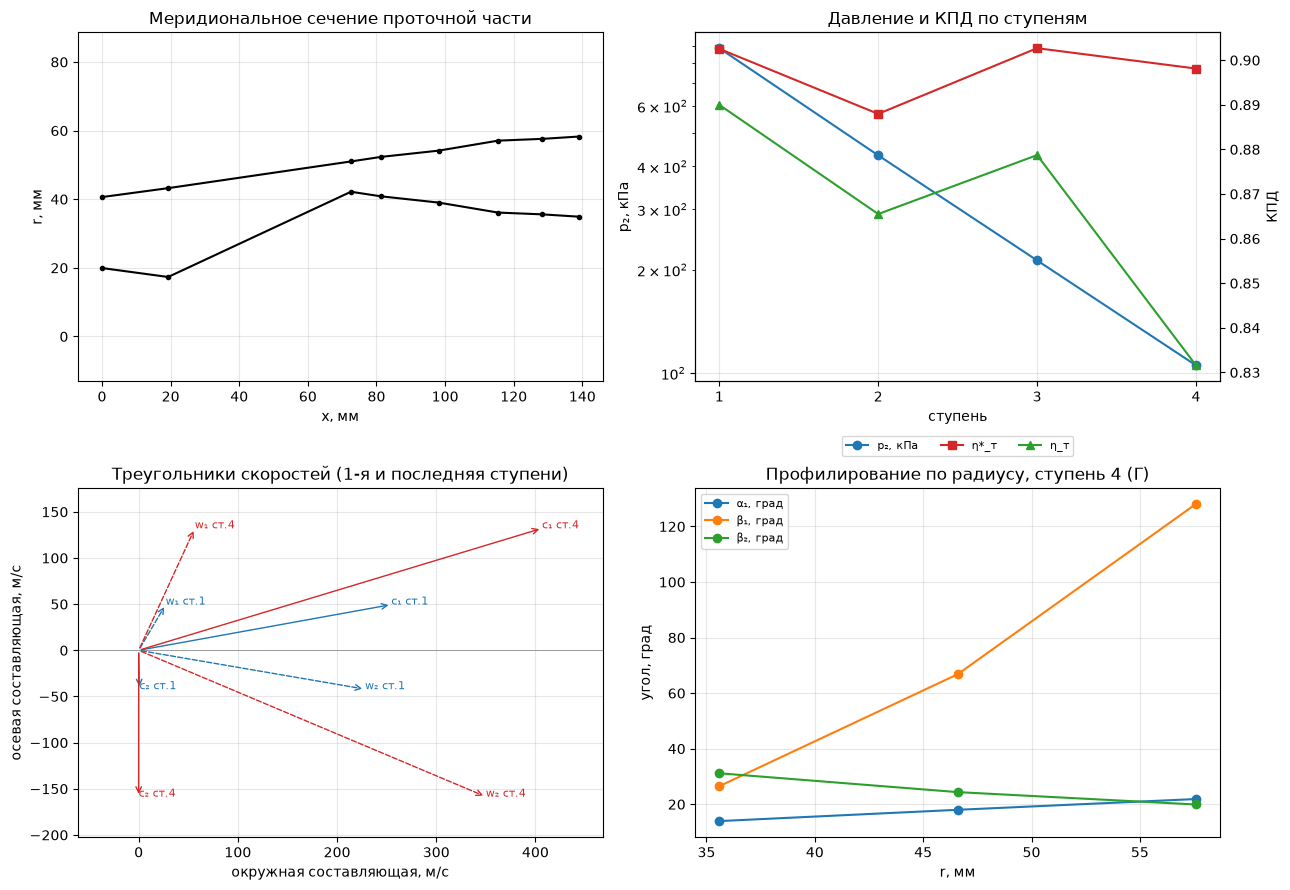

In [17]:
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
a = ax[0, 0]  # меридиональное сечение
a.plot(контур_df.x * 1e3, контур_df.r_н * 1e3, "k-o", ms=3)
a.plot(контур_df.x * 1e3, контур_df.r_в * 1e3, "k-o", ms=3)
a.set(xlabel="x, мм", ylabel="r, мм", title="Меридиональное сечение проточной части")
a.set_aspect("equal", adjustable="datalim")
a.grid(alpha=0.3)
a = ax[0, 1]  # давление и КПД по ступеням
ид = np.arange(1, z + 1)
л_p, = a.plot(ид, [s["p2"] / 1e3 for s in ступени], "o-", color="tab:blue", label="p₂, кПа")
a.set(xlabel="ступень", ylabel="p₂, кПа", title="Давление и КПД по ступеням", xticks=ид)
a.set_yscale("log")
a2 = a.twinx()
л_1, = a2.plot(ид, [s["η_т_п"] for s in ступени], "s-", color="tab:red", label="η*_т")
л_2, = a2.plot(ид, [s["η_т"] for s in ступени], "^-", color="tab:green", label="η_т")
a2.set_ylabel("КПД")
a.legend(handles=[л_p, л_1, л_2], loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=3, fontsize=8)
a.grid(alpha=0.3)
a = ax[1, 0]  # треугольники скоростей
точки = [(0.0, 0.0)]
for idx, цвет in ((0, "tab:blue"), (z - 1, "tab:red")):
    s = ступени[idx]
    for vx, vy, лаб, ls in ((s["c1u"], s["c1a"], "c₁", "-"), (s["c1u"] - s["u1"], s["c1a"], "w₁", "--"),
                            (s["c2u"], -s["c2a"], "c₂", "-"), (s["c2u"] + s["u2"], -s["c2a"], "w₂", "--")):
        a.annotate("", xy=(vx, vy), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=цвет, ls=ls))
        a.text(vx, vy, f"{лаб} ст.{idx+1}", color=цвет, fontsize=8)
        точки.append((vx, vy))
a.plot(*zip(*точки), ".", alpha=0)  # для автомасштаба
a.margins(0.15)
a.set(xlabel="окружная составляющая, м/с", ylabel="осевая составляющая, м/с", title="Треугольники скоростей (1-я и последняя ступени)")
a.axhline(0, color="gray", lw=0.5)
a.grid(alpha=0.3)
a = ax[1, 1]  # углы по радиусу в последней ступени
df = профили[закон_ст[-1]][-1]
for пар, цвет in (("α₁, град", "tab:blue"), ("β₁, град", "tab:orange"), ("β₂, град", "tab:green")):
    a.plot(df.loc["r, мм"], df.loc[пар], "-o", color=цвет, label=пар)
a.set(xlabel="r, мм", ylabel="угол, град", title=f"Профилирование по радиусу, ступень {z} ({закон_ст[-1]})")
a.legend(fontsize=8)
a.grid(alpha=0.3)
fig.tight_layout()
plt.show()